### O que esse código faz, no geral?

Imagine que você tem uma coleção de flores (o famoso dataset Iris) e quer que o computador aprenda, sozinho, a identificar a espécie de uma flor baseado em medidas como comprimento e largura das pétalas. Esse código faz exatamente isso — ele **treina um modelo** para classificar flores em categorias.

1. Importações:

In [31]:
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

Aqui você está "chamando as ferramentas" que vai usar. O `sklearn` (scikit-learn) é uma biblioteca cheia de algoritmos prontos. Pense nele como uma caixa de ferramentas de IA.

2. Carregando os dados:

In [32]:
X, y = load_iris(return_X_y=True)

`X` contém as características (features) de cada flor — as medidas. `y` contém os rótulos — qual é a espécie de cada flor.

3. Dividindo em treino e teste:

In [33]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

Esse é um conceito fundamental: você **nunca** deve testar seu modelo com os mesmos dados que usou para treiná-lo. Imagine estudar para uma prova e o professor te dar exatamente as mesmas questões do gabarito — você passaria, mas não aprendeu nada de verdade. O `test_size=0.33` significa que 33% dos dados ficam reservados para o teste, e 67% para o treino.

Existe também o parâmetro `random_state=42` que garante que a divisão dos dados seja sempre a mesma toda vez que você rodar o código, tornando os experimentos reproduzíveis.

4. Criando e treinando o modelo:

In [34]:
lr = LogisticRegression()
lr.fit(X_train, y_train)

LogisticRegression()

`lr = LogisticRegression()` cria o modelo "zerado". O `lr.fit(X_train, y_train)` é o momento em que o aprendizado acontece de verdade — o modelo analisa os dados de treino e ajusta seus parâmetros internos para aprender os padrões.

5. Fazendo previsões

In [35]:
y_pred = lr.predict(X_test)

O método `.predict()` recebe as características (`X_test`). Faz sentido: na vida real, você teria as medidas da flor, mas não saberia a espécie — justamente o que quer descobrir.

### Como ver os resultados?

Após corrigir o código, você pode avaliar o desempenho do modelo assim:

Acurácia: 1.0

Relatório de Classificação:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        15
   virginica       1.00      1.00      1.00        16

    accuracy                           1.00        50
   macro avg       1.00      1.00      1.00        50
weighted avg       1.00      1.00      1.00        50



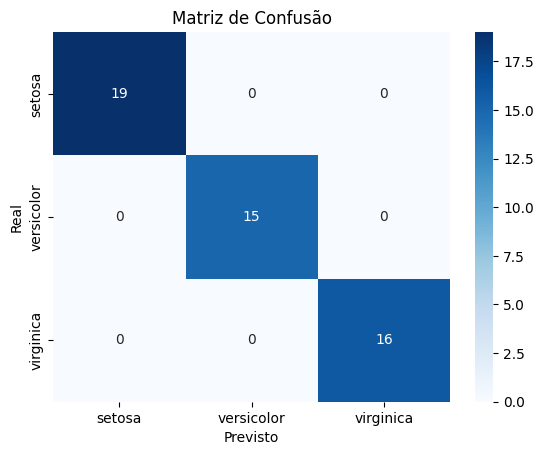

In [36]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Acurácia geral — percentual de acertos
print("Acurácia:", accuracy_score(y_test, y_pred))

# 2. Relatório completo por classe — precisão, recall e F1-score
print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred,
      target_names=['setosa', 'versicolor', 'virginica']))

# 3. Matriz de confusão — mostra onde o modelo errou
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["setosa", "versicolor", "virginica"],
            yticklabels=["setosa", "versicolor", "virginica"])
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.title("Matriz de Confusão")
plt.show()

A **acurácia** te diz um número entre 0 e 1 (ou 0% a 100%) representando a proporção de acertos, em percentual, de quantas flores foram classificadas corretamente. O **relatório de classificação** vai mais fundo e mostra métricas como precisão e recall para cada espécie de flor individualmente. A **matriz de confusão** é especialmente interessante: ela revela com quais espécies o modelo se confunde, ou seja, onde estão os erros.